[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Elheims/scikit-learn-cookbook/blob/main/03.%20Dimensionality%20Reduction/ch03_dimensionality_reduction.ipynb)

# Chapter 3: Dimensionality Reduction Techniques

**Book:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt) — Chapter 3, pp. 68–91

**What you will learn in this chapter:**
- Why dimensionality reduction matters: simpler data, lower cost, less overfitting, visualisation
- The difference between feature *selection* and feature *extraction*
- How PCA finds the directions of maximum variance, and how to read explained variance
- How LDA uses class labels to maximise class separability, and how it differs from PCA
- How t-SNE embeds high-dimensional data in 2-D for visualisation, and what it cannot do
- How to choose between PCA, LDA and t-SNE, and what the trade-offs are for model performance
- Practical exercises: PCA + logistic regression on Iris, and t-SNE + K-Means on handwritten digits

## Chapter summary

| Section | Core idea | Key API |
|---|---|---|
| Introduction | Fewer, better features; selection vs extraction | — |
| PCA | Unsupervised, linear; orthogonal directions of maximum variance | `PCA` |
| LDA | Supervised, linear; maximise between-class vs within-class variance | `LinearDiscriminantAnalysis` |
| t-SNE | Unsupervised, non-linear; preserve local neighbourhoods for visualisation | `TSNE` |
| Selecting a technique | Decision flow + comparison table | — |
| Impact on performance | Complexity vs interpretability, speed vs accuracy, overfitting vs underfitting | — |
| Practical exercises | PCA + logistic regression (Iris), t-SNE + K-Means (digits) | `Pipeline`, `KMeans` |

**How this notebook is organised.** Each section has a summary, the book's code reproduced and executed, and a *Theory* cell.
Cells marked **Extension** are not in the book's code; I added them so a concept the book only describes can be seen working.
Places where the book's text or code is inaccurate are flagged with **Book correction** (collected again at the end).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

print("scikit-learn version:", sklearn.__version__)
print("NumPy version       :", np.__version__)

scikit-learn version: 1.9.1
NumPy version       : 2.5.3


## 1. Introduction to dimensionality reduction

**Summary.** Dimensionality reduction reduces the number of features (dimensions) while keeping as much *relevant* information as possible.
The book gives four reasons:

1. **Simplifying data** — easier to interpret and analyse.
2. **Reducing computational cost** — fewer features, faster training, less memory.
3. **Improving performance** — removing irrelevant/redundant features lowers the risk of overfitting.
4. **Enhancing visualisation** — we can only plot 2–3 dimensions.

Two families:

| | Feature **selection** | Feature **extraction** |
|---|---|---|
| Idea | Keep a *subset* of the original features, unchanged | *Transform* the features into a new, smaller space |
| Methods | filter (statistics), wrapper (e.g. RFE), embedded (e.g. Lasso) | PCA, LDA, t-SNE |
| Result | original, interpretable columns | new synthetic columns (combinations) |

The selection methods in more detail (book): **filter** methods score features by their statistical properties (e.g. correlation with the target); **wrapper** methods evaluate feature subsets by training a model and
measuring its performance (e.g. recursive feature elimination); **embedded** methods select features as part of model training (e.g. Lasso, Chapter 5). There are also **hybrid** methods that combine several of these techniques —
the book only notes that they exist and does not cover them, and neither does this chapter. (Feature *selection* was practised in Chapter 2 with `RFE` and `SelectFromModel`.)

Recommended workflow (book): (1) assess the dimensionality and its problems, (2) choose selection or extraction, (3) apply scikit-learn's tool,
(4) train models on original and reduced data and compare.

**Extension — the curse of dimensionality.** One reason high dimensions are troublesome: distances lose meaning. For random points, the farthest
point is barely farther away than the nearest one as the number of dimensions grows.

In [2]:
from scipy.spatial.distance import cdist

rng = np.random.default_rng(0)
rows = []
for d in (2, 5, 10, 50, 100, 500, 1000):
    pts = rng.random((500, d))
    dist = cdist(pts[:1], pts[1:]).ravel()          # distances from one point to all others
    rows.append({"dimensions": d, "nearest": dist.min(), "farthest": dist.max(),
                 "farthest / nearest": dist.max() / dist.min()})
pd.DataFrame(rows).set_index("dimensions").round(2)

,nearest,farthest,farthest / nearest
dimensions,,,
2,0.01,0.94,67.13
5,0.23,1.42,6.10
10,0.61,1.99,3.26
50,2.11,3.45,1.63
100,3.47,4.78,1.37
500,8.37,9.77,1.17
1000,11.97,13.33,1.11


The ratio collapses towards 1: in 1000 dimensions "nearest" and "farthest" neighbours are almost equally far, which hurts every distance-based method (KNN, K-Means, SVM-RBF).

### Theory
* **Curse of dimensionality.** The volume of the space grows exponentially with the number of features, so a fixed number of samples becomes sparse;
  models need exponentially more data to cover it, distances concentrate (as shown), and overfitting becomes easy.
* **Intrinsic dimension.** Real data usually lies near a lower-dimensional surface (manifold) inside the big feature space — e.g. handwritten
  digits have 64 pixel features but far fewer degrees of freedom (stroke thickness, slant, shape). Dimensionality reduction tries to find that surface.
* **Selection vs extraction trade-off:** selection keeps interpretability (a column is still "age"); extraction can compress more but produces mixed features.
* All techniques below must be **fit on training data only** and, for supervised evaluation, placed inside a `Pipeline` (see Section 4 and the leakage note in Section 3).

## 2. Transforming datasets with PCA

**Summary.** PCA (*Principal Component Analysis*) re-expresses the data in a new coordinate system whose axes — the **principal components** —
are orthogonal directions ordered by how much variance they capture. Keeping only the first few components gives a compact representation.

### Getting ready — the Wine dataset
178 samples of wines from 3 cultivars, described by 13 chemical measurements.

In [3]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine
import warnings

np.random.seed(2024)
warnings.simplefilter(
    action='ignore', category=FutureWarning)

wine = load_wine()
df_wine = pd.DataFrame(
    data=wine.data, columns=wine.feature_names)
target_wine = wine.target
display(df_wine.head(10))

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0
9,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0


In [4]:
print("shape:", df_wine.shape, "| classes:", list(wine.target_names), "| samples per class:", np.bincount(target_wine))
display(df_wine.describe().T[["mean", "std", "min", "max"]].round(2))

shape: (178, 13) | classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')] | samples per class: [59 71 48]


,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


The features live on very different scales (`proline` in the hundreds–thousands, `hue` around 1) — which is why the book *always scales before PCA*.

### How to do it…
PCA is wrapped in a `Pipeline` with a `StandardScaler`, reducing 13 dimensions to 2.

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

pca_pipeline = Pipeline([
    (
        'scaler', StandardScaler()
    ),  # Always scale before PCA
    (
        'pca', PCA(n_components=2)
    )   # Reduce to 2 dimensions
])
X_pca = pca_pipeline.fit_transform(df_wine)
print(X_pca.shape)

(178, 2)


Now the book's visualisation. (The book prints a typographic quote around `"Classes"` that is a syntax error when copied; I used straight quotes.)

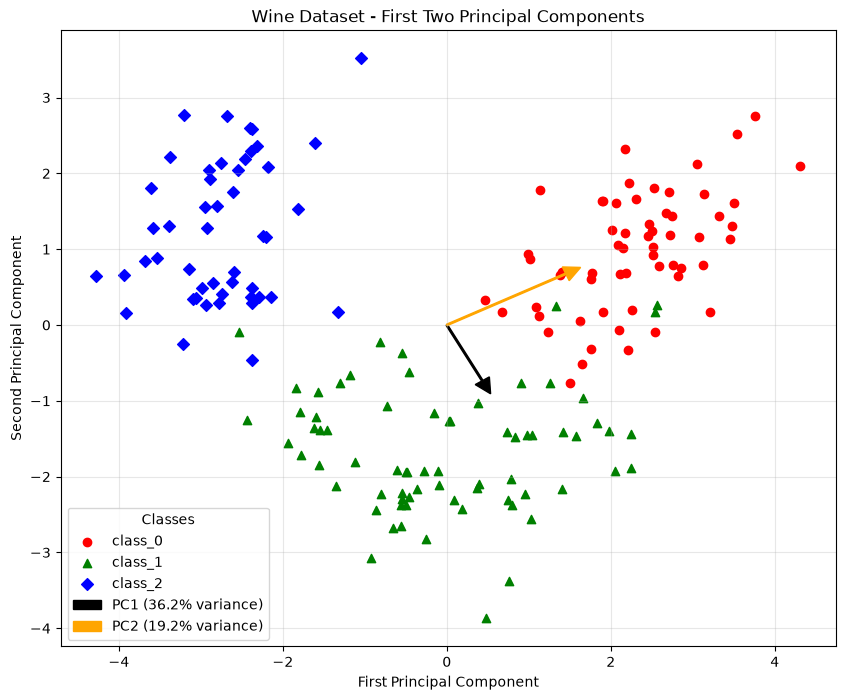

In [6]:
plt.figure(figsize=(10, 8))
shapes = ['o', '^', 'D']
colors = ['r', 'g', 'b']

for i, (shape, color) in enumerate(zip(shapes, colors)):
    plt.scatter(
        X_pca[target_wine == i, 0],
        X_pca[target_wine == i, 1],
        c=color, marker=shape,
        label=wine.target_names[i]
    )

pca = pca_pipeline.named_steps['pca']
origin = np.zeros(2)  # Origin point for vectors
arrow_colors = ['black', 'orange']

scaling = 3
for i, (component, ratio) in enumerate(zip(
    pca.components_, pca.explained_variance_ratio_)
):
    plt.arrow(
        origin[0], origin[1],
        component[0] * scaling,
        component[1] * scaling,
        color=arrow_colors[i],
        width=0.02,
        head_width=0.2, head_length=0.2,
        label=f'PC{i+1} ({ratio:.1%} variance)'
    )
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('Wine Dataset - First Two Principal Components')
plt.legend(title="Classes")
plt.grid(True, alpha=0.3)
plt.show()

> **Book correction (arrows).** `pca.components_[i]` is the *i-th principal component expressed in the original 13-feature space*.
> The book plots `component[0]` and `component[1]` — i.e. the loadings of the first **two original features** (`alcohol`, `malic_acid`) on that component —
> as an (x, y) arrow. That does not show the direction of PC1/PC2 in this plot (those *are* the x and y axes). The meaningful arrows are **feature loadings**:
> for each feature `j`, the arrow `(components_[0, j], components_[1, j])`. That is called a **biplot**; it is built in the Extension below.

Even in 2-D the three cultivars are visibly separated by the first two components alone, without PCA ever looking at the labels.

### How it works…
The five steps of PCA (book): **standardise → covariance matrix → eigenvalues/eigenvectors → pick top components → project**.
Next the explained-variance bar chart from the book:

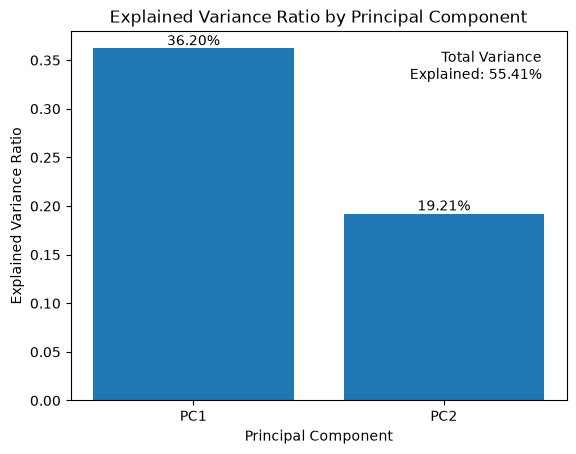

In [7]:
pca = pca_pipeline.named_steps['pca']
explained_variance_ratio = pca.explained_variance_ratio_

cumulative_variance = np.sum(explained_variance_ratio)

fig, ax = plt.subplots()
x = np.arange(1, len(explained_variance_ratio) + 1)
y = explained_variance_ratio
bars = ax.bar(x, y)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2.,
        height, f'{height:.2%}',
        ha='center', va='bottom'
    )

ax.text(
    0.95, 0.95,
    f'Total Variance\nExplained: {cumulative_variance:.2%}',
    transform=ax.transAxes,
    ha='right', va='top',
    bbox=dict(
        facecolor='white', alpha=0.8, edgecolor='none'
    )
)

ax.set_xticks(x)
ax.set_xticklabels(['PC1', 'PC2'])
ax.set_xlabel('Principal Component')
ax.set_ylabel('Explained Variance Ratio')
ax.set_title('Explained Variance Ratio by Principal Component')
plt.show()

The first two components explain **55.41 %** of the variance (book's Figure 3.3) — "more than half". Note that the variable called `cumulative_variance`
in the book is just the *total* of the two ratios, not a cumulative curve; the curve is drawn in the Extension below.

### Figure 3.4 — PCA on just two features, before and after
The book describes this figure and leaves its code in its repository. I rebuilt it: pick two standardised features, rotate them to their own principal axes.

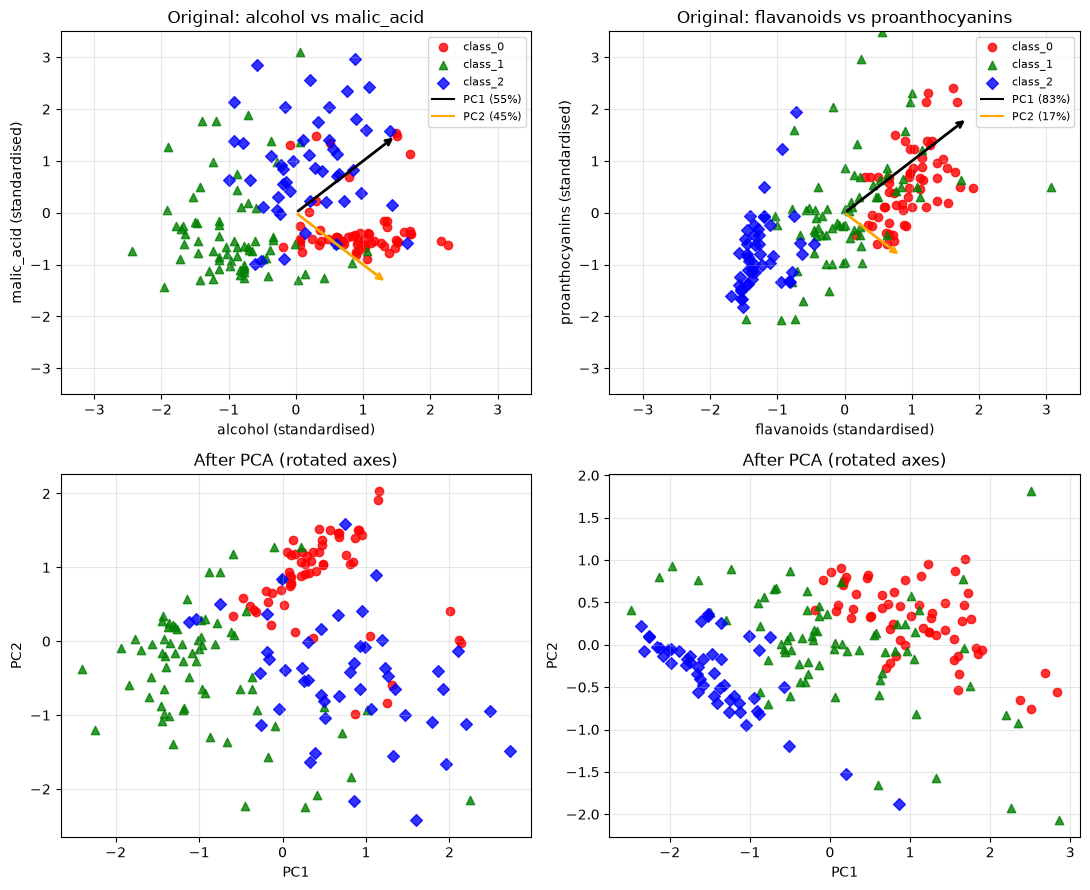

In [8]:
pairs = [("alcohol", "malic_acid"), ("flavanoids", "proanthocyanins")]
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
Xs = StandardScaler().fit_transform(df_wine)
cols = list(df_wine.columns)

for k, (f1, f2) in enumerate(pairs):
    Z = Xs[:, [cols.index(f1), cols.index(f2)]]
    p2 = PCA(n_components=2).fit(Z)
    T = p2.transform(Z)
    for i, (shape, color) in enumerate(zip(shapes, colors)):
        axes[0, k].scatter(Z[target_wine == i, 0], Z[target_wine == i, 1], c=color, marker=shape, label=wine.target_names[i], alpha=.8)
        axes[1, k].scatter(T[target_wine == i, 0], T[target_wine == i, 1], c=color, marker=shape, label=wine.target_names[i], alpha=.8)
    axes[0, k].set_xlabel(f1 + " (standardised)"); axes[0, k].set_ylabel(f2 + " (standardised)")
    axes[0, k].set_title(f"Original: {f1} vs {f2}")
    for j, c in enumerate(["black", "orange"]):                       # principal axes drawn in the ORIGINAL 2-D space
        v = p2.components_[j] * 2 * np.sqrt(p2.explained_variance_[j])
        axes[0, k].annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=2))
        axes[0, k].plot([], [], color=c, label=f"PC{j+1} ({p2.explained_variance_ratio_[j]:.0%})")
    axes[1, k].set_xlabel("PC1"); axes[1, k].set_ylabel("PC2"); axes[1, k].set_title("After PCA (rotated axes)")
    axes[0, k].legend(fontsize=8)
    axes[0, k].set_xlim(-3.5, 3.5); axes[0, k].set_ylim(-3.5, 3.5)       # annotations do not auto-scale the axes
for a in axes.ravel(): a.grid(alpha=.3)
plt.tight_layout(); plt.show()

Top row: original standardised features with the principal axes drawn as arrows. Bottom row: the same points after PCA — only a *rotation* (no information is lost with 2 → 2
components); the first axis now carries the largest spread. Dimensionality reduction would come from then dropping PC2.

### Extension — PCA verified by hand
The book lists the algorithm (covariance → eigendecomposition). Doing it with NumPy reproduces `sklearn`'s numbers exactly (up to the arbitrary sign of eigenvectors):

In [9]:
Xs = StandardScaler().fit_transform(df_wine)
cov = np.cov(Xs, rowvar=False)                       # 13 x 13 covariance matrix (n-1 denominator)
eigvals, eigvecs = np.linalg.eigh(cov)               # eigh: for symmetric matrices, ascending order
order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[order], eigvecs[:, order]

full_pca = PCA().fit(Xs)
print("eigenvalues (manual) :", eigvals[:4].round(4))
print("explained_variance_  :", full_pca.explained_variance_[:4].round(4))
print("variance ratio manual:", (eigvals / eigvals.sum())[:2].round(4), "-> first two sum to", (eigvals / eigvals.sum())[:2].sum().round(4))
print("same directions up to sign:", np.allclose(np.abs(eigvecs[:, :2].T), np.abs(full_pca.components_[:2])))
print("components orthogonal (W W^T = I):", np.allclose(full_pca.components_ @ full_pca.components_.T, np.eye(13)))

eigenvalues (manual) : [4.7324 2.5111 1.4542 0.9242]
explained_variance_  : [4.7324 2.5111 1.4542 0.9242]
variance ratio manual: [0.362  0.1921] -> first two sum to 0.5541
same directions up to sign: True
components orthogonal (W W^T = I): True


### Extension — how many components? Scree plot and cumulative variance
With only two components we kept 55 %. The usual way to choose `n_components` is to look at the *cumulative* explained variance.

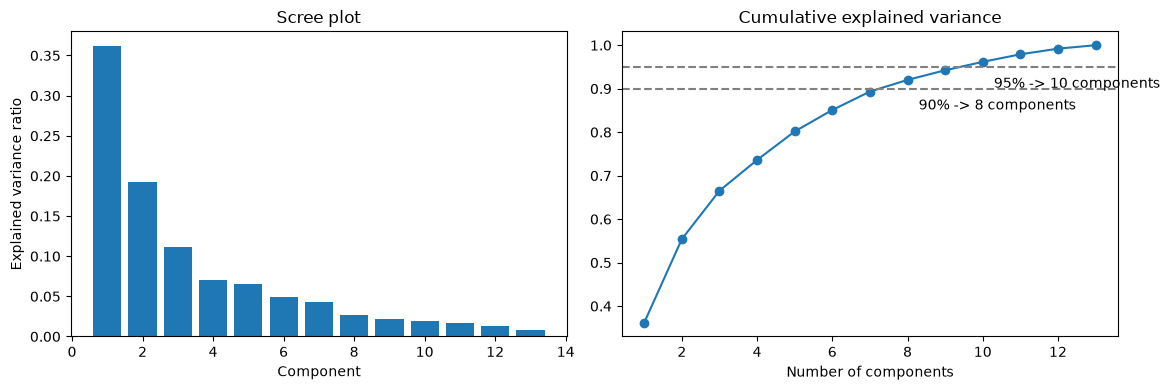

PCA(n_components=0.95) kept 10 components


In [10]:
ratios = full_pca.explained_variance_ratio_
cum = np.cumsum(ratios)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(1, 14), ratios); ax[0].set_title("Scree plot"); ax[0].set_xlabel("Component"); ax[0].set_ylabel("Explained variance ratio")
ax[1].plot(range(1, 14), cum, "o-")
for thr in (0.90, 0.95):
    k = int(np.searchsorted(cum, thr) + 1)
    ax[1].axhline(thr, ls="--", c="grey"); ax[1].annotate(f"{thr:.0%} -> {k} components", (k, thr), textcoords="offset points", xytext=(8, -15))
ax[1].set_title("Cumulative explained variance"); ax[1].set_xlabel("Number of components")
plt.tight_layout(); plt.show()

# sklearn can pick the number for you: a float in (0, 1) = fraction of variance to keep
auto = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=0.95))]).fit(df_wine)
print("PCA(n_components=0.95) kept", auto.named_steps["pca"].n_components_, "components")

So the book's remark "in most cases the first two principal components capture the most variation" is a simplification: here two components give 55 %, and about 8 are
needed for 90 %. Two components are enough to *see* the classes, not to preserve the data.

### Extension — what do the components mean? Loadings and a proper biplot
Each component is a weighted sum of the standardised features; the weights are the *loadings* (`components_`).

,PC1,PC2
flavanoids,0.423,-0.003
total_phenols,0.395,0.065
od280/od315_of_diluted_wines,0.376,-0.164
proanthocyanins,0.313,0.039
nonflavanoid_phenols,-0.299,0.029
hue,0.297,-0.279
proline,0.287,0.365
malic_acid,-0.245,0.225
alcalinity_of_ash,-0.239,-0.011
alcohol,0.144,0.484


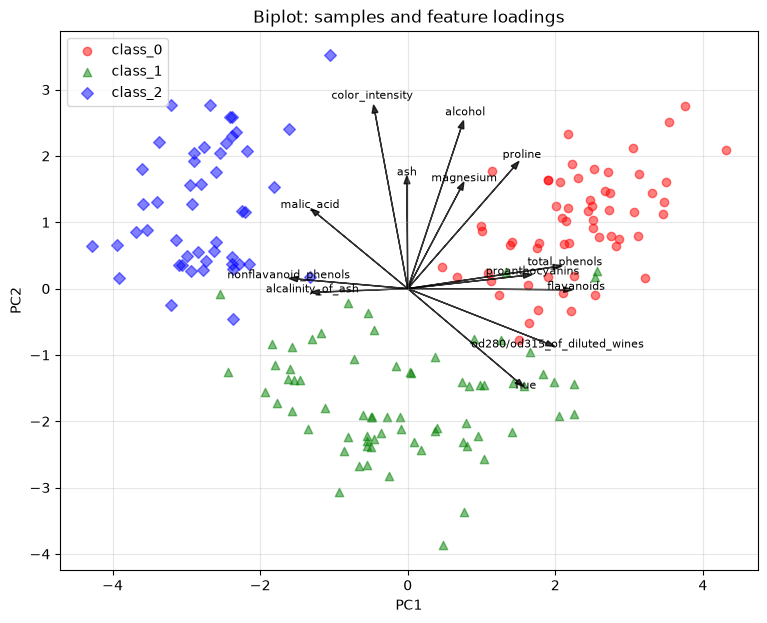

In [11]:
loadings = pd.DataFrame(full_pca.components_[:2].T, index=df_wine.columns, columns=["PC1", "PC2"])
display(loadings.round(3).sort_values("PC1", key=abs, ascending=False))

fig, ax = plt.subplots(figsize=(9, 7))
for i, (shape, color) in enumerate(zip(shapes, colors)):
    ax.scatter(X_pca[target_wine == i, 0], X_pca[target_wine == i, 1], c=color, marker=shape, alpha=.5, label=wine.target_names[i])
for name, (l1, l2) in loadings.iterrows():                           # arrow per FEATURE (this is the correct biplot)
    ax.arrow(0, 0, l1 * 5, l2 * 5, color="k", head_width=0.08, alpha=.8)
    ax.text(l1 * 5.4, l2 * 5.4, name, fontsize=8, ha="center")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("Biplot: samples and feature loadings"); ax.legend(); ax.grid(alpha=.3)
plt.show()

Features with long arrows pointing the same way (e.g. `flavanoids`, `total_phenols`, `od280/od315...`) are positively correlated and drive PC1;
`alcohol`/`proline`/`color_intensity` contribute strongly to PC2. This is the interpretability that PCA offers — and its limit: a component is a *mixture*.

### Extension — reconstruction error (the cost of dropping components)

In [12]:
Xs = StandardScaler().fit_transform(df_wine)
for k in (2, 5, 8, 13):
    p = PCA(n_components=k).fit(Xs)
    recon = p.inverse_transform(p.transform(Xs))
    print(f"{k:2d} components: variance kept = {p.explained_variance_ratio_.sum():.1%}   mean squared reconstruction error = {np.mean((Xs - recon) ** 2):.4f}")

 2 components: variance kept = 55.4%   mean squared reconstruction error = 0.4459
 5 components: variance kept = 80.2%   mean squared reconstruction error = 0.1984
 8 components: variance kept = 92.0%   mean squared reconstruction error = 0.0798
13 components: variance kept = 100.0%   mean squared reconstruction error = 0.0000


### Theory
* **Goal.** Find a unit vector $w_1$ that maximises the variance of the projected data $\mathrm{Var}(Xw)$, then $w_2\perp w_1$ with the next largest variance, etc.
* **Solution.** With centred (and, here, standardised) data $X\in\mathbb R^{n\times p}$ the covariance matrix is $\Sigma=\dfrac{1}{n-1}X^\top X$. The components are the **eigenvectors** of $\Sigma$:
  $$\Sigma\,w_k=\lambda_k\,w_k$$
  and the eigenvalue $\lambda_k$ is the variance captured along $w_k$. Explained variance ratio $=\lambda_k/\sum_j\lambda_j$.
* **Projection.** $Z=XW_k$ where $W_k$ holds the first $k$ eigenvectors as columns. Approximate reconstruction: $\hat X=ZW_k^\top$.
* **In practice** scikit-learn uses the **SVD** $X=U S V^\top$ (more stable): components are the rows of $V^\top$ and $\lambda_k=s_k^2/(n-1)$.
* **Why standardise first?** Variance is scale-dependent: an unscaled `proline` (variance in the tens of thousands) would swallow PC1 entirely. Standardising gives each feature unit variance, so PCA then works on the *correlation* matrix.
* **Properties:** linear, unsupervised (ignores labels), components are orthogonal and uncorrelated; sensitive to outliers and scaling; high variance does **not** always mean high usefulness for prediction (a low-variance direction can carry the class signal).
* **Use cases:** noise reduction, compression, de-correlating features before regression, visualisation, speed-up.
* **Hyper-parameters:** `n_components` (int, float for a variance fraction, or `'mle'`), `whiten=True` (rescale components to unit variance), `svd_solver` (`'randomized'` for big data).

### Hands-on workflow (from the book)
Understand the dimensionality → scale → `PCA` → inspect explained variance and plot → use the reduced features in a model (done in Sections 6 and 7).

## 3. Maximizing class separability with LDA

**Summary.** LDA (*Linear Discriminant Analysis*) is **supervised**: it uses the class labels to find the axes along which the classes are best separated —
maximising the distance *between* class means while minimising the spread *within* each class. PCA ignores labels and maximises total variance.

### How to do it…
Same wine data, scaled then LDA with 2 components. The maximum number of LDA components is `min(n_features, n_classes − 1)` = min(13, 2) = **2**.

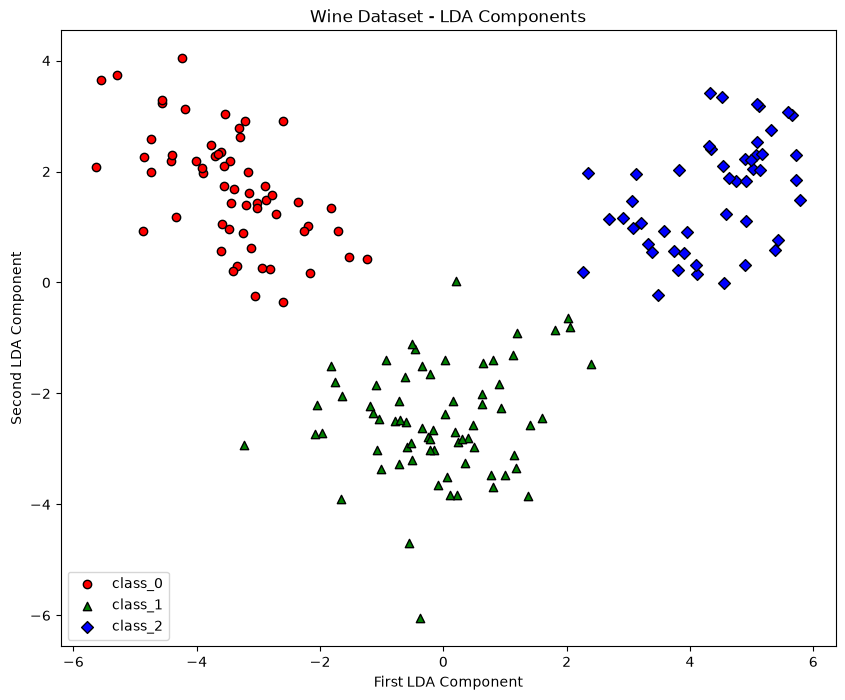

In [13]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

X_wine, y_wine = wine.data, wine.target

lda_pipeline_wine = Pipeline([
    ('scaler', StandardScaler()),
    ('lda', LinearDiscriminantAnalysis(n_components=2))
    # min(n_features, n_classes - 1) for wine dataset is 2
])
X_lda_wine = lda_pipeline_wine.fit_transform(
    X_wine, y_wine
)

plt.figure(figsize=(10, 8))
shapes = ['o', '^', 'D']
colors = ['r', 'g', 'b']
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(
        X_lda_wine[mask, 0], X_lda_wine[mask, 1],
        c=color, marker=shape, edgecolor='black',
        label=wine.target_names[i]
    )
plt.xlabel('First LDA Component')
plt.ylabel('Second LDA Component')
plt.title('Wine Dataset - LDA Components')
plt.legend()
plt.show()

After LDA the three classes form three tight, well-separated groups (book's Figure 3.5).

### Differences between PCA and LDA — side by side

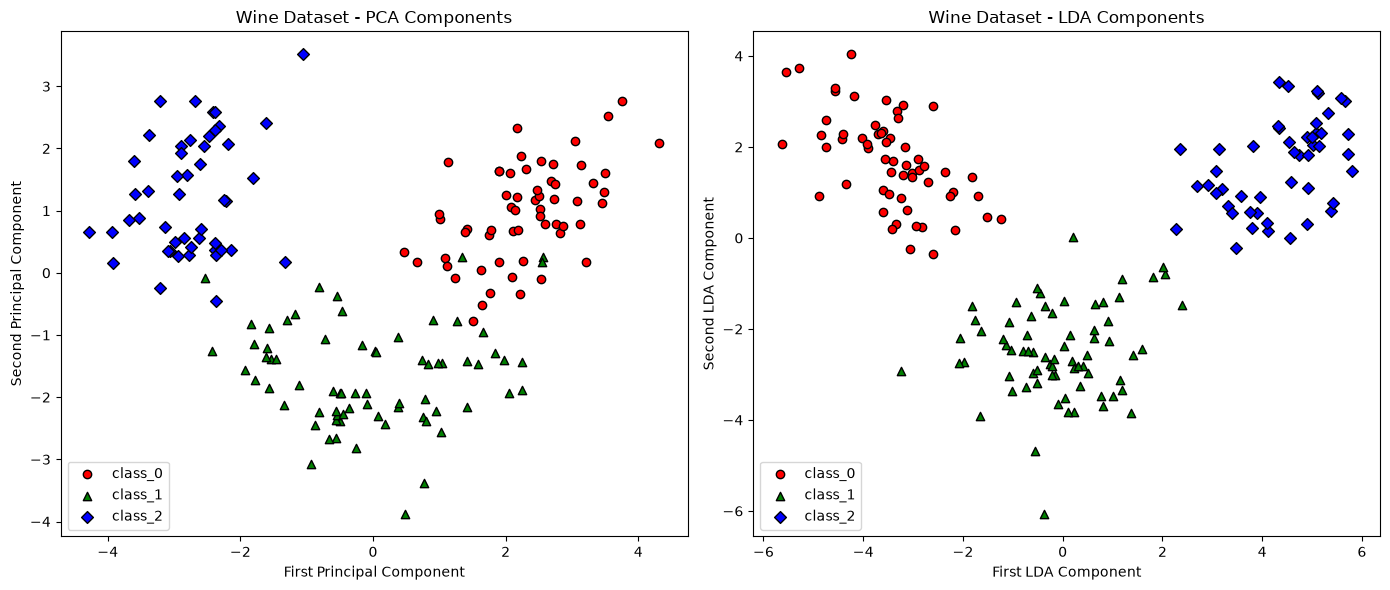

In [14]:
plt.figure(figsize=(14, 6))
plt.subplot(121)
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        c=color, marker=shape, edgecolor='black',
        label=wine.target_names[i]
    )
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('Wine Dataset - PCA Components')
plt.legend()

plt.subplot(122)
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(
        X_lda_wine[mask, 0], X_lda_wine[mask, 1],
        c=color, marker=shape, edgecolor='black',
        label=wine.target_names[i]
    )
plt.xlabel('First LDA Component')
plt.ylabel('Second LDA Component')
plt.title('Wine Dataset - LDA Components')
plt.legend()
plt.tight_layout()
plt.show()

As the book says, LDA's separation is "a little more striking" — partly because it *used the labels* to build the picture.

**Extension — is that separation real? Evaluate on unseen data.** A plot on the training data flatters a supervised method. The honest test: put the reducer *inside*
the pipeline, so it is re-fit on each training fold only, and score a classifier on held-out folds.

In [15]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression

cv = StratifiedKFold(5, shuffle=True, random_state=2024)
candidates = {
    "no reduction (13 features)": Pipeline([("s", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))]),
    "PCA(2)  -> LogReg":          Pipeline([("s", StandardScaler()), ("r", PCA(2)), ("clf", LogisticRegression(max_iter=1000))]),
    "LDA(2)  -> LogReg":          Pipeline([("s", StandardScaler()), ("r", LinearDiscriminantAnalysis(n_components=2)), ("clf", LogisticRegression(max_iter=1000))]),
}
pd.DataFrame({k: cross_val_score(p, X_wine, y_wine, cv=cv) for k, p in candidates.items()}).agg(["mean", "std"]).round(3)

,no reduction (13 features),PCA(2) -> LogReg,LDA(2) -> LogReg
mean,0.983,0.972,0.994
std,0.016,0.028,0.013


Both 2-D reductions keep accuracy high on unseen folds; LDA is typically the better 2-D representation for *classification* because it is built for it.
Note the difference in validity: fitting **LDA on the whole dataset and then cross-validating the classifier** would leak the labels of the validation folds into the features — a form of data
leakage that PCA (no labels) suffers from far less. Hence: always use the pipeline for supervised reducers.

**Extension — how much of the class-separating power does each LDA axis hold?**

In [16]:
lda = lda_pipeline_wine.named_steps["lda"]
print("LDA explained_variance_ratio_ (between-class variance share):", lda.explained_variance_ratio_.round(3))
print("LDA is also a classifier; training accuracy of lda.predict:", round(lda_pipeline_wine.score(X_wine, y_wine), 3))

LDA explained_variance_ratio_ (between-class variance share): [0.687 0.313]
LDA is also a classifier; training accuracy of lda.predict: 1.0


### Theory
* **Scatter matrices.** For $C$ classes with means $\mu_c$, overall mean $\mu$, and $n_c$ samples in class $c$:
  $$S_W=\sum_{c}\sum_{x\in c}(x-\mu_c)(x-\mu_c)^\top\quad(\text{within}),\qquad S_B=\sum_c n_c(\mu_c-\mu)(\mu_c-\mu)^\top\quad(\text{between}).$$
* **Fisher criterion.** Find $w$ maximising
  $$J(w)=\frac{w^\top S_B\,w}{w^\top S_W\,w}$$
  — large separation between class means relative to the spread inside classes. The solutions are the eigenvectors of $S_W^{-1}S_B$.
* **Number of components.** $S_B$ has rank at most $C-1$, so LDA gives at most $\min(p,\,C-1)$ useful axes (2 for Wine, Iris and 3 classes; 9 for digits).
* **Assumptions (book):** each class is Gaussian with a **common covariance matrix**; this is why features are standardised, and why LDA is also a good *classifier* (Bayes-optimal under those assumptions). If covariances differ a lot, QDA fits better.
* **PCA vs LDA:**

| | PCA | LDA |
|---|---|---|
| Supervision | unsupervised | supervised (needs labels) |
| Objective | maximise variance | maximise class separability $S_B/S_W$ |
| Max components | $\min(n,p)$ | $\min(p,C-1)$ |
| Axes | orthogonal | not necessarily orthogonal (in the original space) |
| Typical use | exploration, compression, noise removal | pre-processing for classification |
| Leakage risk | low | **high** if fitted outside the CV loop |

* **Limitations:** linear boundaries only; sensitive to outliers; needs $n>p$ (or shrinkage: `solver="eigen", shrinkage="auto"`) so that $S_W$ is invertible; useless for regression targets.

### Hands-on workflow (from the book)
Labelled data → standardise → `LinearDiscriminantAnalysis` → inspect class separation in the reduced space → use the reduced features in a classifier (see the cross-validated comparison above).

## 4. t-SNE and data visualization

**Summary.** t-SNE (*t-distributed Stochastic Neighbor Embedding*) is a **non-linear**, unsupervised technique for *visualising* high-dimensional data in 2-D or 3-D.
It converts distances between points into probabilities of "being neighbours" and arranges the low-dimensional points so those probabilities are matched — similar points end up close.

### Getting ready — the digits dataset
1 797 images of handwritten digits 0–9, each 8×8 pixels (64 features).

(1797, 64) | classes: [0 1 2 3 4 5 6 7 8 9] | pixel value range: 0.0 to 16.0


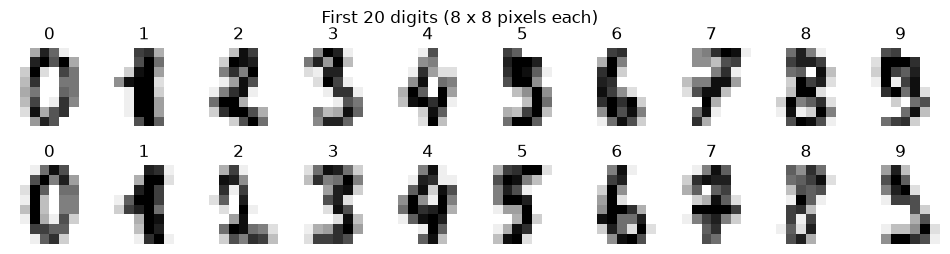

In [17]:
from sklearn.datasets import load_digits

digits = load_digits()
print(digits.data.shape, "| classes:", np.unique(digits.target), "| pixel value range:", digits.data.min(), "to", digits.data.max())

fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
for ax, img, lab in zip(axes.ravel(), digits.images, digits.target):
    ax.imshow(img, cmap="gray_r"); ax.set_title(lab); ax.axis("off")
plt.suptitle("First 20 digits (8 x 8 pixels each)"); plt.show()

> **Book correction.** The book calls this dataset "MNIST". It is **not**: MNIST has 70 000 images of 28×28 pixels. `load_digits` is the small UCI *Optical Recognition of
> Handwritten Digits* set (1 797 images, 8×8). The book's own description of the data (8×8 blocks, integers 0–16) actually describes this smaller dataset correctly.

### How to do it…

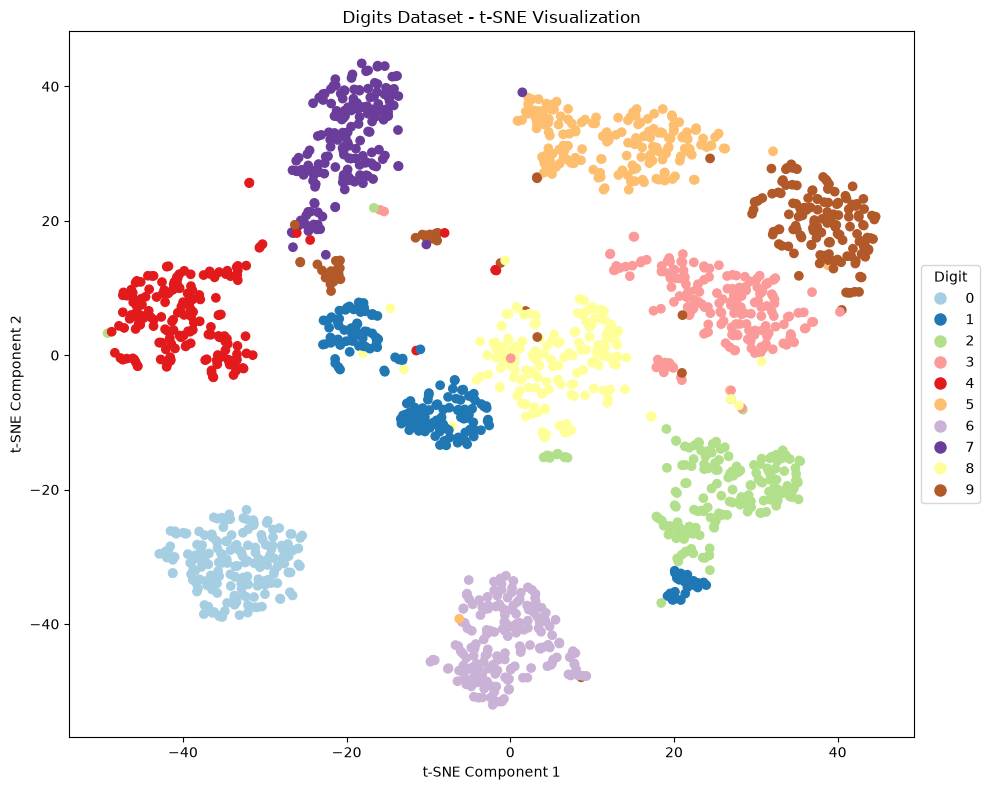

In [18]:
from sklearn.manifold import TSNE

tsne_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('tsne', TSNE(n_components=2, random_state=2024))
])
X_tsne = tsne_pipeline.fit_transform(digits.data)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    X_tsne[:, 0], X_tsne[:, 1],
    c=digits.target, cmap='Paired',
    label=digits.target
)
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.title('Digits Dataset - t-SNE Visualization')

legend_elements = [
    plt.Line2D(
        [0], [0], marker='o', color='w',
        markerfacecolor=plt.cm.Paired(i/9),
        label=str(i), markersize=10
    )
    for i in range(10)
]
plt.legend(
    handles=legend_elements,
    title='Digit', loc='center left',
    bbox_to_anchor=(1, 0.5)
)
plt.tight_layout()
plt.show()

The ten digits form ten clear islands even though t-SNE **never saw the labels** (colours are only painted on afterwards). The book says "Similar to LDA, t-SNE excels at class separation" —
the correct reading is that t-SNE reveals the cluster structure that is already in the pixels; unlike LDA it is not optimising for the classes.

### How it works…
The three stages from the book: **(1)** compute pairwise similarities in high dimensions, **(2)** find a low-dimensional layout that preserves them, **(3)** clusters of similar points emerge.

**Extension — what t-SNE can and cannot do.**

TSNE has transform(): False | PCA has transform(): True


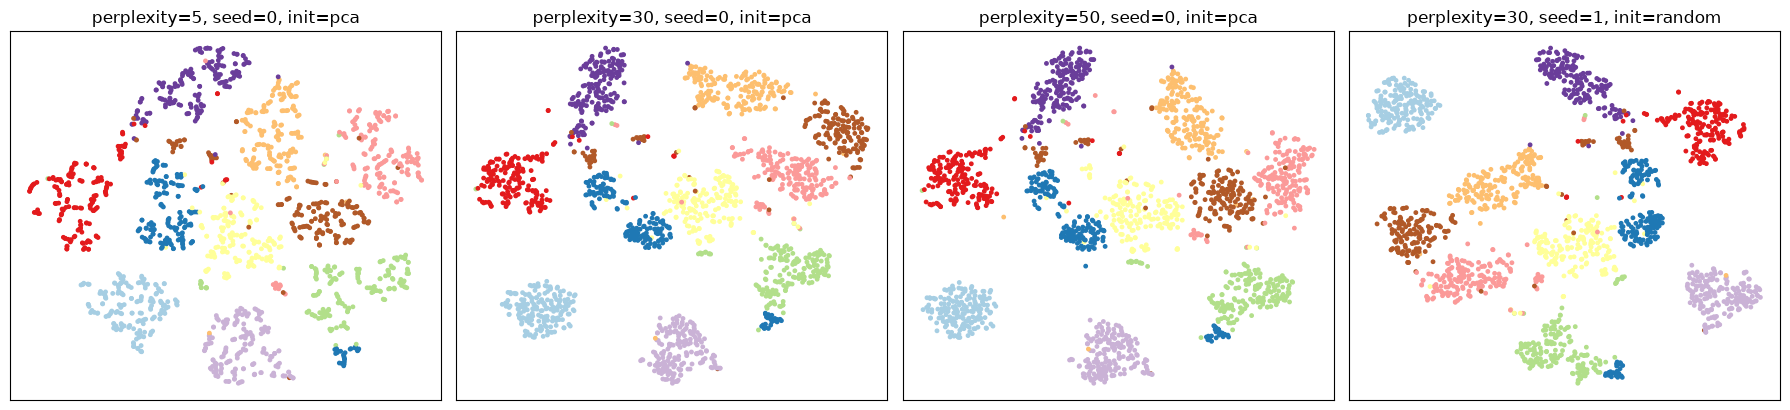

In [19]:
import time

# 1) t-SNE has no transform(): it embeds exactly the points it was given, so new data cannot be projected later.
print("TSNE has transform():", hasattr(TSNE, "transform"), "| PCA has transform():", hasattr(PCA, "transform"))

# 2) the result depends on the random seed and on `perplexity`
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (perp, seed, init) in zip(axes, [(5, 0, "pca"), (30, 0, "pca"), (50, 0, "pca"), (30, 1, "random")]):
    t0 = time.time()
    emb = TSNE(n_components=2, perplexity=perp, random_state=seed, init=init).fit_transform(StandardScaler().fit_transform(digits.data))
    ax.scatter(emb[:, 0], emb[:, 1], c=digits.target, cmap="Paired", s=6)
    ax.set_title(f"perplexity={perp}, seed={seed}, init={init}"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

Small perplexity (5) fragments some digits into several small groups; 30–50 gives clean clusters. The last panel uses a different seed with `init="random"` (scikit-learn's default
`init="pca"` makes the map nearly deterministic): the islands land in different places, but the same digits remain neighbours.
So **global layout, island sizes and the distances between islands should not be interpreted** — only the neighbourhood structure.

**Extension — the common recipe: PCA first, then t-SNE.** Reduce to ~30 dimensions with PCA (removes noise, cuts cost), then embed. On this small dataset (1 797 × 64)
the time difference is negligible; the benefit appears with hundreds or thousands of features and many more samples.

In [20]:
Xd = StandardScaler().fit_transform(digits.data)
t0 = time.time(); TSNE(random_state=2024).fit_transform(Xd);                         t_full = time.time() - t0
Xp = PCA(n_components=30, random_state=0).fit_transform(Xd)
t0 = time.time(); emb_pca_tsne = TSNE(random_state=2024).fit_transform(Xp);          t_pca = time.time() - t0
print(f"t-SNE on 64 features: {t_full:.1f}s   |   PCA(30) + t-SNE: {t_pca:.1f}s")

t-SNE on 64 features: 3.9s   |   PCA(30) + t-SNE: 3.9s


### Theory
* **High-dimensional similarities.** For points $x_i$, a Gaussian centred at $x_i$ gives the conditional probability that $x_j$ is its neighbour:
  $$p_{j|i}=\frac{\exp(-\lVert x_i-x_j\rVert^2/2\sigma_i^2)}{\sum_{k\ne i}\exp(-\lVert x_i-x_k\rVert^2/2\sigma_i^2)},\qquad p_{ij}=\frac{p_{j|i}+p_{i|j}}{2n}.$$
  The bandwidth $\sigma_i$ of each point is tuned so that the distribution has a chosen **perplexity** (a smooth "effective number of neighbours", typically 5–50).
* **Low-dimensional similarities.** Points $y_i$ in 2-D use a heavy-tailed **Student-t** (1 degree of freedom) kernel:
  $$q_{ij}=\frac{(1+\lVert y_i-y_j\rVert^2)^{-1}}{\sum_{k\ne l}(1+\lVert y_k-y_l\rVert^2)^{-1}}.$$
  The heavy tails let moderately distant points sit far apart, which solves the *crowding problem* of the original SNE.
* **Objective.** Minimise the Kullback–Leibler divergence $\mathrm{KL}(P\Vert Q)=\sum_{i\ne j}p_{ij}\log\dfrac{p_{ij}}{q_{ij}}$ by gradient descent (with *early exaggeration* in the first iterations).
  The objective is non-convex, so the result depends on the initialisation/seed.
* **Properties:** non-linear; focuses on **local** structure (KL penalises placing true neighbours far apart much more than placing non-neighbours close); $O(n^2)$ naively (Barnes–Hut makes it $\approx O(n\log n)$);
  no `transform` for new data; stochastic; meant for **visualisation**, not for producing features for a downstream model.
* **Reading a t-SNE plot:** clusters = real structure; cluster *sizes*, inter-cluster *distances* and the absolute axes = not meaningful. Try several perplexities.

### Hands-on workflow (from the book)
Understand the data → scale → `TSNE` → scatter plot → analyse clusters. (Example 2 at the end of the chapter does this with K-Means.)

## 5. Selecting the right technique (There's more…)

### The decision flow (book's Figure 3.8) in text form
1. **Do you have labelled data *and* want class separation?** → **Yes: LDA** (supervised, linear, good as classification pre-processing).
2. **No →** *Is the primary goal visualisation in 2-D/3-D?*
   * **Yes →** *Do you need to preserve local structure/clusters?* → **Yes (non-linear): t-SNE** · **No (global structure): PCA**.
   * **No (pre-processing) →** *Need interpretability, speed, or to transform new data?* → **Yes to any: PCA**.

### The book's comparison table (Table 3.1)
| Technique | Type | Purpose | Key features | Best use cases |
|---|---|---|---|---|
| **PCA** | Unsupervised | Dimensionality reduction | Maximises variance; linear combinations of features | Exploratory analysis, noise reduction, feature extraction |
| **LDA** | Supervised | Dimensionality reduction | Maximises class separability; linear discriminants | Classification where class separation matters |
| **t-SNE** | Unsupervised | Visualisation | Non-linear mapping; reveals clusters; preserves local structure | Visualising high-dimensional data, exploratory analysis |

### Guidelines (summary of the book's five questions)
* **Supervised vs unsupervised:** labels + class separation → LDA; no labels → PCA; t-SNE for visualisation either way.
* **Variance vs class separability:** keep variance → PCA; separate classes → LDA; show clusters → t-SNE.
* **Extraction vs visualisation:** PCA and LDA produce usable features; t-SNE is for looking only.
* **Efficiency:** PCA is cheap and scales to large data; LDA needs class means/covariances; t-SNE is iterative and expensive.
* **Interpretability:** PCA components are mixtures (hard to read), LDA discriminants are tied to classes, t-SNE axes mean nothing.

**Practical steps (book):** state the goal → know whether the data is labelled and how big → check compute budget → if unsure, combine methods (e.g. PCA then t-SNE, as shown above) → judge by model metrics or plot clarity.

**Extension — the efficiency claim, measured** on the digits data (fit time, and whether the method can transform new data):

In [21]:
from sklearn.model_selection import train_test_split

Xtr, Xte, ytr, yte = train_test_split(StandardScaler().fit_transform(digits.data), digits.target, test_size=0.3, random_state=2024, stratify=digits.target)
rows = []
for name, est, sup in [("PCA(2)", PCA(2), False), ("LDA(2)", LinearDiscriminantAnalysis(n_components=2), True), ("t-SNE(2)", TSNE(2, random_state=0), False)]:
    t0 = time.time()
    est.fit_transform(Xtr, ytr) if sup else est.fit_transform(Xtr)
    rows.append({"method": name, "fit time (s)": round(time.time() - t0, 2), "uses labels": sup, "can transform new data": hasattr(est, "transform")})
pd.DataFrame(rows).set_index("method")

,fit time (s),uses labels,can transform new data
method,,,
PCA(2),0.00,False,True
LDA(2),0.02,True,True
t-SNE(2),2.94,False,False


## 6. Impact on model performance

**Summary.** Reduction usually gives simpler, faster, less over-fitted models, but can discard useful information. The book frames three trade-offs:

| Trade-off | Benefit of reducing | Risk |
|---|---|---|
| Complexity vs interpretability | simpler, easier to explain | important information lost |
| Training time vs accuracy | faster training, fewer resources | accuracy drops if key features discarded |
| Overfitting vs generalisation | removes noise/irrelevant features → generalises better | too few dimensions → underfitting |

**Extension — all three trade-offs in one experiment.** On the digits data, train logistic regression on PCA outputs with a varying number of components
(inside a pipeline, evaluated with cross-validation) and watch accuracy and training time.

,cv accuracy,std,time (s)
components,,,
1,0.341,0.033,0.246
2,0.535,0.026,0.299
3,0.672,0.039,0.369
5,0.771,0.029,0.354
8,0.824,0.040,0.347
10,0.840,0.035,0.437
15,0.892,0.025,0.291
20,0.899,0.020,0.263
30,0.907,0.027,0.245


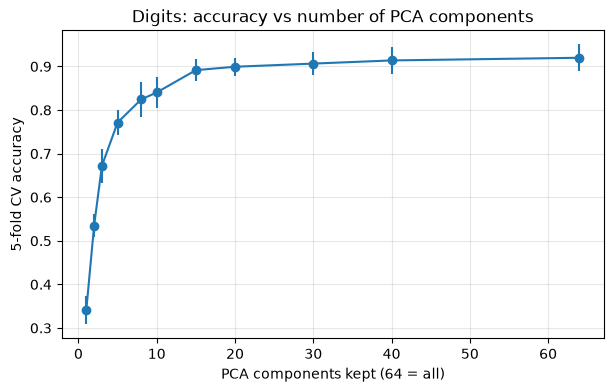

In [22]:
ks = [1, 2, 3, 5, 8, 10, 15, 20, 30, 40, 64]
res = []
for k in ks:
    pipe = Pipeline([("s", StandardScaler()), ("pca", PCA(n_components=k)), ("clf", LogisticRegression(max_iter=2000))])
    t0 = time.time()
    sc = cross_val_score(pipe, digits.data, digits.target, cv=5)
    res.append({"components": k, "cv accuracy": sc.mean(), "std": sc.std(), "time (s)": time.time() - t0})
res = pd.DataFrame(res).set_index("components")
display(res.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(res.index, res["cv accuracy"], yerr=res["std"], fmt="o-")
ax.set_xlabel("PCA components kept (64 = all)"); ax.set_ylabel("5-fold CV accuracy"); ax.set_title("Digits: accuracy vs number of PCA components"); ax.grid(alpha=.3)
plt.show()

Reading the curve:
* **Underfitting zone (1–5 components):** too few dimensions, accuracy is poor.
* **Plateau (≈ 20–40 components):** accuracy is within about 1–2 points of the 64-feature model (≈ 0.90–0.91 vs 0.92) with a model a third to two thirds the size.
* **Beyond the plateau** extra components add little accuracy. Here reducing *never beats* using all 64 features (the digits are fairly clean); with noisier or much wider data a reduced
  model can match or beat the full one. Training time barely changes on a dataset this small — the speed benefit appears at scale.

This is exactly the book's advice: evaluate the accuracy sacrificed relative to the efficiency gained, and choose `n_components` by validation performance, not by habit.

## 7. Practical exercises in dimensionality reduction

The book gives two exercises as *step lists* only (solutions are in its repository). Here is my implementation of both.

### Example 1 — PCA with logistic regression on Iris
Steps (book): load libraries → split → pipeline **without** PCA → pipeline **with** PCA → fit and evaluate both → print results.
(The book notes logistic regression has not been covered yet; it is the subject of Chapter 6. Here it is simply a classifier that takes the (reduced) features.)

In [23]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 1-2. Load and split
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.3, random_state=2024, stratify=iris.target)

# 3. Pipeline without PCA
pipe_no_pca = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000)),
])

# 4. Pipeline with PCA (4 features -> 2 components)
pipe_pca = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=2)),
    ("clf", LogisticRegression(max_iter=1000)),
])

# 5. Fit and evaluate both
for name, p in [("Without PCA (4 features)", pipe_no_pca), ("With PCA (2 components)", pipe_pca)]:
    p.fit(X_train, y_train)
    acc = accuracy_score(y_test, p.predict(X_test))
    # 6. Print the results
    print(f"{name:26s} test accuracy = {acc:.3f}")

print("\nvariance kept by 2 PCs:", pipe_pca.named_steps["pca"].explained_variance_ratio_.sum().round(3))
print("\nClassification report (with PCA):")
print(classification_report(y_test, pipe_pca.predict(X_test), target_names=iris.target_names))

Without PCA (4 features)   test accuracy = 0.956
With PCA (2 components)    test accuracy = 0.911

variance kept by 2 PCs: 0.957

Classification report (with PCA):
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.87      0.87      0.87        15
   virginica       0.87      0.87      0.87        15

    accuracy                           0.91        45
   macro avg       0.91      0.91      0.91        45
weighted avg       0.91      0.91      0.91        45



For a more reliable comparison than one 45-sample test set, repeat with cross-validation (still leak-free because PCA is in the pipeline):

In [24]:
cv = StratifiedKFold(10, shuffle=True, random_state=2024)
for name, p in [("Without PCA", pipe_no_pca), ("PCA(2)", pipe_pca), ("PCA(1)", Pipeline([("s", StandardScaler()), ("pca", PCA(1)), ("clf", LogisticRegression(max_iter=1000))]))]:
    s = cross_val_score(p, iris.data, iris.target, cv=cv)
    print(f"{name:12s} CV accuracy = {s.mean():.3f} +/- {s.std():.3f}")

Without PCA  CV accuracy = 0.960 +/- 0.033
PCA(2)       CV accuracy = 0.920 +/- 0.040
PCA(1)       CV accuracy = 0.920 +/- 0.040


**Take-away.** With 4 features, PCA cannot make the model simpler in a way that helps: reducing to 2 components keeps ≈ 96 % of the variance but costs about 4 points of accuracy
(0.96 → 0.92 in CV; 0.956 → 0.911 on the single split, i.e. 2 of 45 samples). PCA(1) scores the same as PCA(2) here — the first component alone carries most of the class signal, and the
gap between them is far smaller than the fold-to-fold noise (± 0.04). This is the *simplicity vs information* trade-off in miniature: variance kept (96 %) is not the same as class information kept.
PCA pays off on wide data (digits, images, genomics), not on a 4-column table.

### Example 2 — t-SNE for visualisation (+ K-Means)
Steps (book): load libraries → apply K-Means → side-by-side plots → plot with **true** labels → plot with **cluster** labels. I use the digits data (the book says "MNIST").

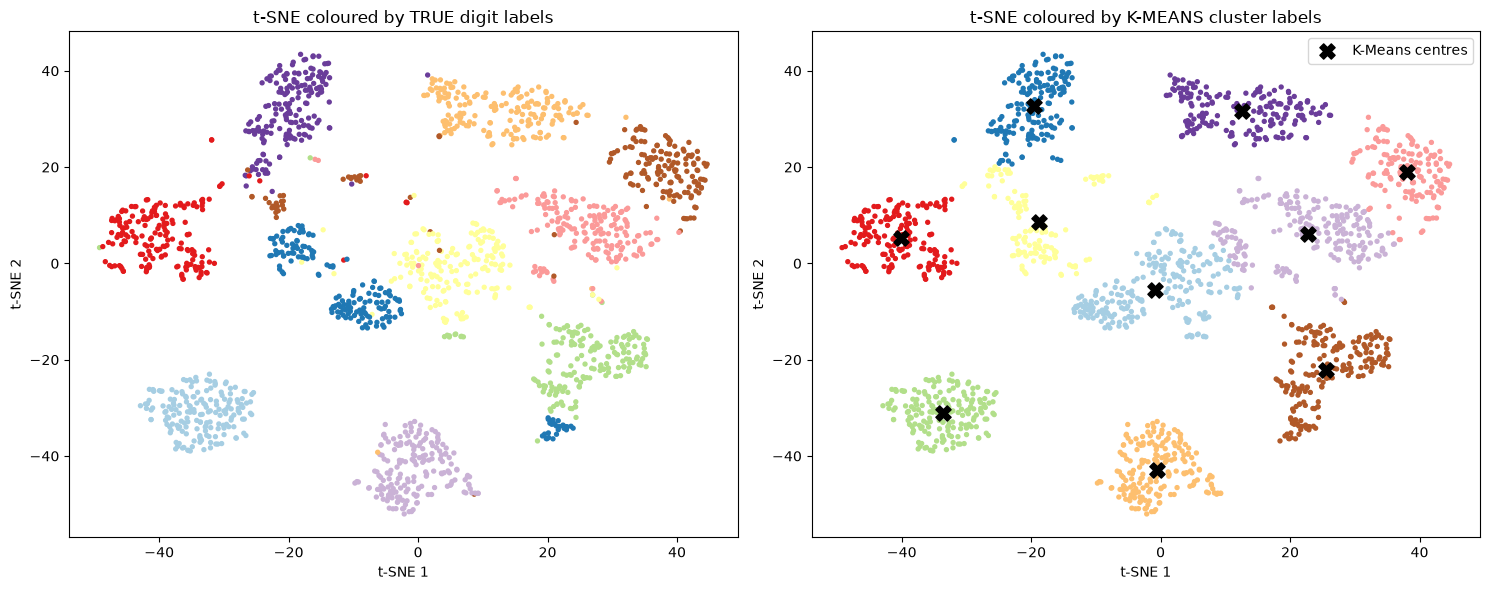

In [25]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

Xd = StandardScaler().fit_transform(digits.data)

# t-SNE embedding (re-use the one made earlier: same settings as the book's pipeline)
emb = X_tsne

# 2. K-Means on the 2-D t-SNE embedding
km = KMeans(n_clusters=10, n_init=10, random_state=2024).fit(emb)

# 3-5. Side-by-side plots: true labels vs cluster labels
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
s1 = axes[0].scatter(emb[:, 0], emb[:, 1], c=digits.target, cmap="Paired", s=8)
axes[0].set_title("t-SNE coloured by TRUE digit labels")
s2 = axes[1].scatter(emb[:, 0], emb[:, 1], c=km.labels_, cmap="Paired", s=8)
axes[1].scatter(*km.cluster_centers_.T, c="k", marker="X", s=120, label="K-Means centres")
axes[1].set_title("t-SNE coloured by K-MEANS cluster labels"); axes[1].legend()
for a in axes: a.set_xlabel("t-SNE 1"); a.set_ylabel("t-SNE 2")
plt.tight_layout(); plt.show()

The two panels look almost identical: K-Means, which never saw the labels, recovers the digit groups from the t-SNE layout. Quantify the agreement with the **Adjusted Rand Index**
(1 = identical partitions, 0 = random) and compare against clustering the raw pixels, i.e. "does the t-SNE step help the clustering?":

In [26]:
km_raw = KMeans(n_clusters=10, n_init=10, random_state=2024).fit(Xd)
km_pca = KMeans(n_clusters=10, n_init=10, random_state=2024).fit(PCA(n_components=30, random_state=0).fit_transform(Xd))

pd.DataFrame({
    "ARI vs true digits": [adjusted_rand_score(digits.target, km_raw.labels_),
                           adjusted_rand_score(digits.target, km_pca.labels_),
                           adjusted_rand_score(digits.target, km.labels_)],
}, index=["K-Means on 64 raw (scaled) pixels", "K-Means on PCA(30)", "K-Means on t-SNE 2-D"]).round(3)

,ARI vs true digits
K-Means on 64 raw (scaled) pixels,0.46
K-Means on PCA(30),0.57
K-Means on t-SNE 2-D,0.77


Clustering in the t-SNE space matches the true digits much better than clustering the raw pixels, because t-SNE has already "unfolded" the non-linear structure that K-Means
(which assumes round, convex clusters) cannot find in 64-D.

> **Caveat.** This is a *visual/exploratory* result. t-SNE has no `transform`, so this embedding cannot be applied to new images; for a deployable classifier use PCA/LDA features in a
> pipeline (Section 6) or a model on the raw features.

### Theory (for the exercises)
* **Why PCA can barely hurt Iris** — the two largest eigenvalues hold most of the variance, so a rank-2 approximation reconstructs the data almost perfectly.
* **K-Means after t-SNE** is a common exploratory recipe (find groups, then inspect them), but clusters of a t-SNE map must be validated on the original features, because t-SNE can fabricate apparent clusters at low perplexity (see the perplexity experiment).
* **Adjusted Rand Index** compares two partitions by counting pairs of samples that are grouped together/apart in both, corrected for chance.

## Chapter takeaways
1. **Reduce for four reasons:** simplicity, speed, generalisation and visualisation — but always check what accuracy you give up.
2. **PCA** (unsupervised, linear) rotates the data onto orthogonal axes of maximal variance; scale first; choose `n_components` from the cumulative explained-variance curve.
3. **LDA** (supervised, linear) maximises between-class vs within-class variance, giving at most `C − 1` axes; it is powerful for classification but must be fitted inside the CV loop to avoid leakage.
4. **t-SNE** (unsupervised, non-linear) is for *looking*: it preserves local neighbourhoods, has no `transform`, and its distances/sizes are not meaningful.
5. **Choosing:** labelled + class separation → LDA; visualise clusters → t-SNE; everything else (pre-processing, interpretability, speed, new data) → PCA; combining (PCA → t-SNE) is common.
6. **Always evaluate** the reduced representation by model performance on held-out data (Sections 3, 6, 7).

### Book corrections noted in this notebook
| Where | Book says / does | Actually |
|---|---|---|
| PCA scatter | arrows `(component[0], component[1])` presented as the directions of PC1/PC2 | those are the loadings of the first two *features* on each PC; the meaningful arrows are per-feature loadings (biplot) |
| Variance bar chart | variable `cumulative_variance` | it is the *total* explained variance of the 2 components, not a cumulative curve |
| "first two PCs capture most variation" | generalisation | on Wine they capture 55 %; ~8 components are needed for 90 % |
| Digits dataset | called "MNIST" | `load_digits` is the small UCI 8×8 digits set (1 797 images), not MNIST (70 000 × 28×28) |
| t-SNE | "Similar to LDA, t-SNE excels at class separation" | t-SNE never uses labels; it reveals existing cluster structure |
| `plt.legend(title="Classes")` | printed with typographic quotes | straight quotes are required to run |

*Next: Chapter 4 — Building Models with Distance Metrics and Nearest Neighbors.*